# 사출 하락 크기 · 무하락 검증 · 사출 없는 하락 (P1, 9/10~10/06)

이 노트북에서 답하는 것:
1. **사출 신호(S1)가 있으면 압력이 얼마나 떨어지나** — 연휴 전/후, `dPT1` vs `dPT2`. `dPT1` 하나만으로 충분한가?
2. **연휴 후 "사출했는데 전혀 안 떨어짐" 12% 는 진짜인가** — 날짜별, 많은 샘플로 확인
3. **사출이 없는데 떨어진 경우**는 정상 틱 대비 얼마나 되고, `Pair_Inj_Flag`·`dSV2`·`FT_Settled` 를 넣으면 얼마나 줄어드나 (크기 구간별, 연휴 전/후)
4. **그래도 설명 안 되는 하락은 언제 생기나** — 샷 안 위치, 사출 전후, FOAMING 단계, 시간대, 레시피, 날짜

**데이터·정의**
- 생산 AE 와 같은 틱 (생산 태그 8개 + 사출 태그, "사출 태그만 바뀐 행" 제거) — `code_ongoing/inj_feat_lib.py`
- 짝펌프 사출 `Shot_Injection_HD1_P2` 는 따로 받아 시간으로 붙임 (`inj_feat_pull_pair.py`). 확인: **S2(`Shot_Injection_On_HD1`) = S1 OR P2** 가 모든 틱에서 성립, S1 과 P2 는 동시에 켜진 적 없음.
- `dPT1` = PT(t)−PT(t−1), `dPT2` = PT(t)−PT(t−2), 같은 샷 안에서만. 단위는 압력 눈금(정수).
- **큰 하락 = dPT1 ≤ −5 눈금.** 사출·SV변경·짝펌프 사출이 없는 안정 틱에서 dPT1 ≤ −5 는 약 3% (하위 2.5% 분위가 −5, 하위 5% 가 −4).
- 계산·그림 코드: `code_ongoing/inj_feat_q4.py`

In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
from inj_feat_q4 import *
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
T = load_ticks()
ev = s1_events(T)
J = off_ticks(T)
print(f'BuildUp 틱 {len(T):,} · S1 사출 이벤트 {len(ev):,} (연휴 전 {(ev.era=="연휴 전").sum():,} / 후 {(ev.era=="연휴 후").sum():,}) · S1 OFF 판정 틱 {len(J):,}')

C:\Users\taetk\Documents\KTA_Train\parkkt\code_ongoing\inj_feat_q4.py:57: RuntimeWarning: All-NaN slice encountered
  rows.append((s, e, e - s + 1, np.nanmin(d1[s:e + 1]), np.nanmin(d2[s:e + 1]),
C:\Users\taetk\Documents\KTA_Train\parkkt\code_ongoing\inj_feat_q4.py:58: RuntimeWarning: All-NaN slice encountered
  np.nanmin(d1[pre]) if pre else np.nan, np.nanmin(d1[post]) if post else np.nan,


BuildUp 틱 893,883 · S1 사출 이벤트 59,160 (연휴 전 36,857 / 후 22,303) · S1 OFF 판정 틱 695,889


## 1. 사출하면 압력이 얼마나 떨어지나

이벤트 = S1 이 켜져 있는 연속 틱 (보통 2틱). 각 이벤트에서 **S1 ON 틱들 중 가장 큰 하락**을 쟀다 — AE 가 `Inj_Flag=1` 인 틱에서 보게 될 값.

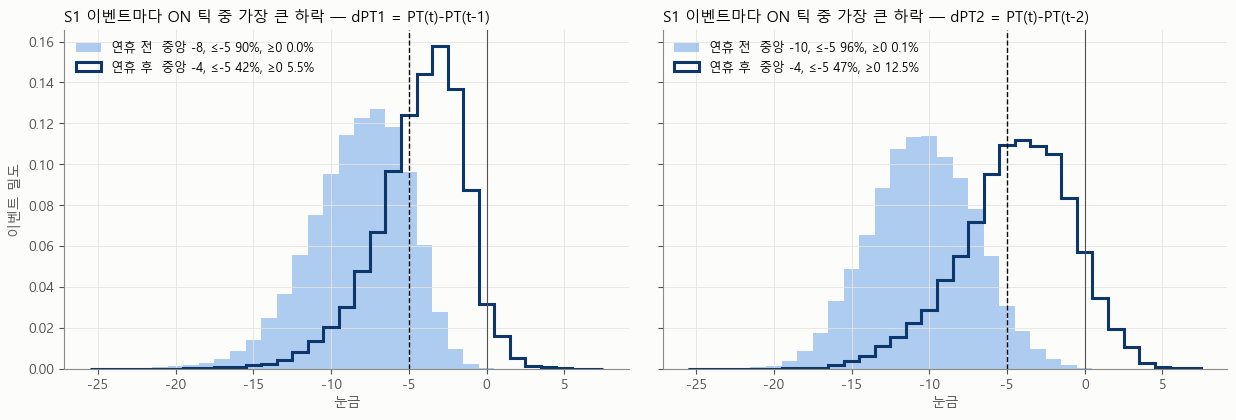

In [2]:
fig_drop_dist(ev); plt.show()

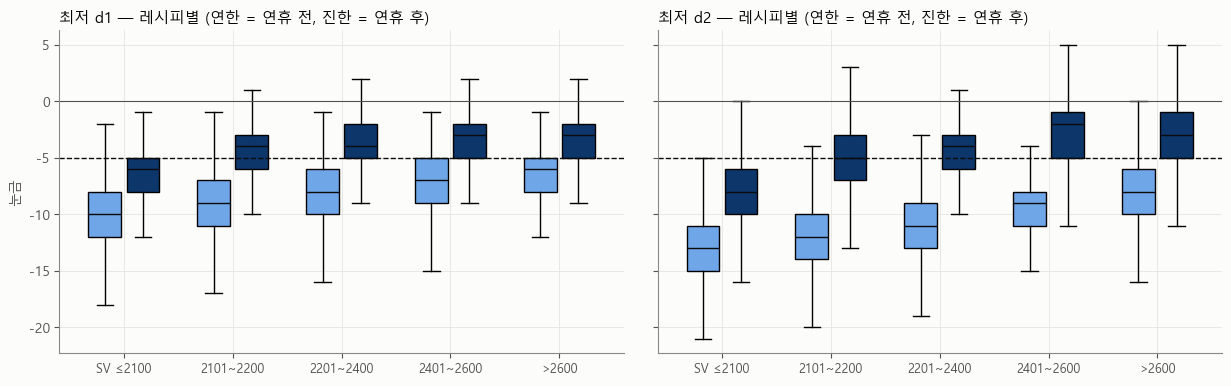

In [3]:
fig_drop_by_sv(ev); plt.show()

### 하락이 S1 의 몇 번째 틱에 오나

In [4]:
p = on_tick_profile(T, ev)
p.pivot_table(index='위치', columns='구간', values=['dPT1 평균', '≤-5 %', 'S1 ON %'], sort=False).round(1)

dPT1 평균      ≤-5 %       S1 ON %       
구간        연휴 전 연휴 후  연휴 전  연휴 후    연휴 전   연휴 후
위치                                            
S1 전 2     4.9  6.6   3.6   3.7     0.0    0.0
S1 전 1     0.2  0.5   3.2   2.8     0.0    0.0
S1 시작     -3.5  0.3  42.3   9.7   100.0  100.0
S1 후 1    -6.0 -3.3  58.8  32.9   100.0  100.0
S1 후 2     3.4  2.0   2.7   2.3    34.0   34.0
S1 후 3     5.2  1.1   0.5   4.7     5.3    6.5
S1 후 4     0.6  0.1   2.3   3.1     0.7    0.7

- **연휴 전**: S1 첫 틱 −3.5, 둘째 틱 −6.0 — 두 틱 모두 떨어진다.
- **연휴 후**: 첫 틱은 거의 0 (+0.3), **둘째 틱에서만** −3.3. 하락이 1틱(0.5초) 늦게, 더 작게 온다.
- S1 이 꺼진 직후(+2, +3)는 회복(+).

### `dPT1` 만으로 충분한가

In [5]:
dpt1_vs_dpt2_table(T, ev)

,이벤트 ≤-5 (dPT1)%,이벤트 ≤-5 (dPT2)%,이벤트 ≤-3 (dPT1)%,이벤트 ≤-3 (dPT2)%,이벤트 ≥0 (dPT1)%,이벤트 ≥0 (dPT2)%,MI 플래그↔dPT1,MI 플래그↔dPT2,"MI 플래그↔(dPT1,dPT2)"
구간,,,,,,,,,
연휴 전,89.899,96.191,98.714,99.029,0.043,0.117,0.192,0.298,0.325
연휴 후,41.923,46.505,72.107,68.583,5.488,12.541,0.048,0.054,0.077


- **이벤트 단위로는 `dPT1` 만으로 충분하다.** ≤−3 하락을 잡는 비율이 dPT1 98.7% / 72.1% vs dPT2 99.0% / 68.6% (연휴 전/후) — 비슷하거나 오히려 dPT1 이 낫다. "전혀 안 떨어짐(≥0)" 은 dPT1 쪽이 훨씬 적다 (연휴 후 5.5% vs 12.5%).
  - dPT2 가 무하락을 더 많이 보이는 이유: S1 직전 틱이 회복 중(+5)인 경우가 많아, PT(t)−PT(t−2) 에 그 상승이 섞여 하락을 상쇄한다.
- **틱 단위 정보량(MI)은 dPT2 가 더 크다** (연휴 전 0.30 vs 0.19). 하락이 두 틱에 걸쳐 나는 걸 dPT2 는 한 숫자로 합쳐서 보기 때문. 둘 다 넣으면 0.33.
- 결론: **dPT1 단독도 가능하다** (사출 시점에 하락이 있는지는 dPT1 로 충분히 드러남). 다만 dPT2 는 생산 모델에 이미 `Rolling_PT_Diff_3` 로 있으므로 굳이 뺄 이유는 없다 — 빼면 틱 정보량이 연휴 전 기준 약 40% 줄어든다.

## 2. 연휴 후 "사출했는데 전혀 안 떨어짐" — 진짜인가

### 날짜별로 끊어 보면

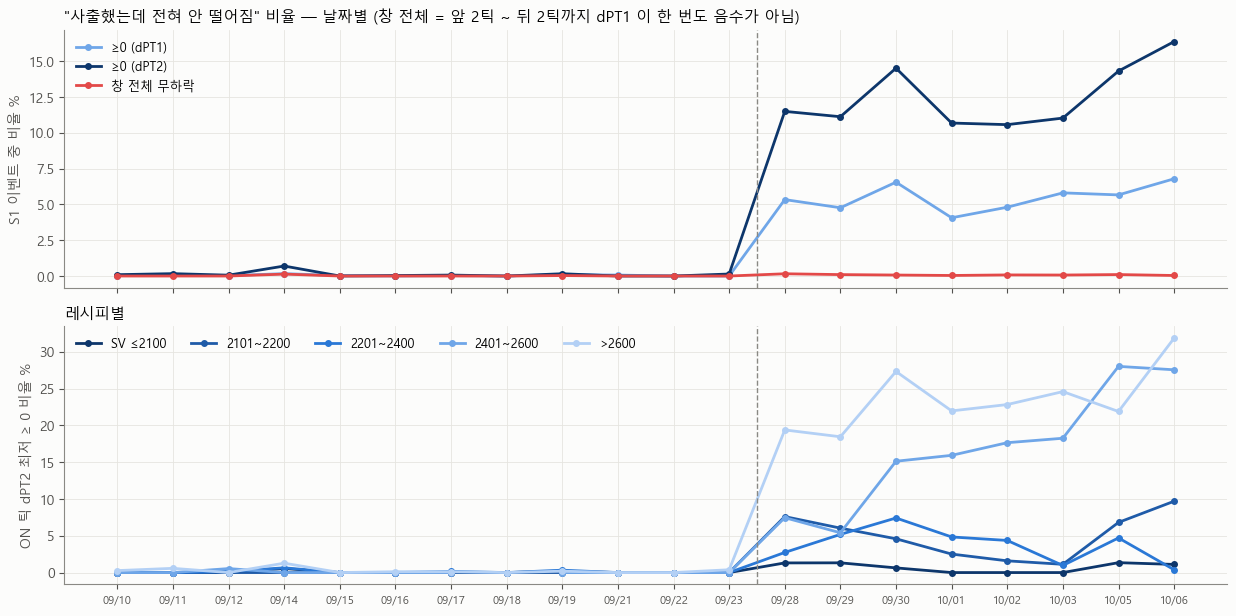

day,2026-09-10,2026-09-11,2026-09-12,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-19,2026-09-21,2026-09-22,2026-09-23,2026-09-28,2026-09-29,2026-09-30,2026-10-01,2026-10-02,2026-10-03,2026-10-05,2026-10-06
≥0 (dPT1),0.0,0.1,0.0,0.2,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.0,5.3,4.8,6.6,4.1,4.8,5.8,5.7,6.8
≥0 (dPT2),0.1,0.2,0.1,0.7,0.0,0.0,0.1,0.0,0.2,0.0,0.0,0.1,11.5,11.1,14.5,10.7,10.6,11.0,14.3,16.4
창 전체 무하락,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.1,0.1,0.0,0.1,0.1,0.1,0.0


In [6]:
fig, d, by_sv = fig_nodrop_daily(ev); plt.show()
display(d.T)

In [7]:
display(by_sv.T)

day,2026-09-10,2026-09-11,2026-09-12,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-19,2026-09-21,2026-09-22,2026-09-23,2026-09-28,2026-09-29,2026-09-30,2026-10-01,2026-10-02,2026-10-03,2026-10-05,2026-10-06
svb,,,,,,,,,,,,,,,,,,,,
SV ≤2100,0.0,0.0,0.0,0.6,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,1.3,1.3,0.6,0.0,0.0,0.0,1.3,1.1
2101~2200,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.6,6.0,4.6,2.5,1.6,1.1,6.8,9.7
2201~2400,0.0,0.0,0.2,0.6,0.0,0.0,0.1,0.0,0.3,0.0,0.0,0.0,2.7,5.2,7.4,4.8,4.4,1.0,4.7,0.4
2401~2600,0.0,0.0,0.5,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,7.5,5.4,15.1,15.9,17.6,18.3,28.0,27.6
>2600,0.3,0.6,0.0,1.3,0.0,0.1,0.1,0.0,0.2,0.0,0.0,0.4,19.4,18.5,27.3,22.0,22.8,24.6,21.9,31.9


- dPT2 기준 무하락이 연휴 전 12일은 매일 0~0.7%, **연휴 후 8일은 매일 10.6~16.4%** (dPT1 기준으로는 4.1~6.8%) — 특정 하루의 문제가 아니라 9/28 부터 계속.
- 레시피별로 보면 연휴 후 SV 2400 초과에서 하루 5~32% (8일 합 21~23%), SV ≤2100 은 연휴 후에도 0~1.3%. 날마다 비율이 출렁이는 건 그날 고유량 레시피를 얼마나 돌렸는지 차이.
- **빨간 선(창 전체 무하락)**: 앞 2틱 ~ 뒤 2틱까지 넓혀서 보면 "한 번도 안 떨어진" 이벤트는 거의 없다 (연휴 후 하루 0~0.2%).

### "전혀 안 떨어짐" 이벤트를 자세히 (연휴 후, ON 틱 dPT2 최저 ≥ 0)

In [8]:
nd = ev[(ev.era == '연휴 후') & (ev.min_d2 >= 0)]
print(f'{len(nd):,}건  (연휴 후 S1 이벤트의 {len(nd)/(ev.era=="연휴 후").sum()*100:.1f}%)')
summ = pd.DataFrame({
    '레시피': nd.svb.value_counts(normalize=True).mul(100).round(1),
}).T
display(summ)
print('S1 ON 틱 수:', nd.n_on.value_counts().to_dict(), '  FOAMING 단계:', nd.F_phase.value_counts().to_dict())
w = pd.DataFrame({'앞 2틱 dPT1 최저': nd.pre_min_d1.describe(), '뒤 2틱 dPT1 최저': nd.post_min_d1.describe(),
                  '창 하락(직전 PT − 창 최저 PT)': nd.win_drop.describe()}).round(1)
display(w)
print('뒤 2틱에서 ≤-3 하락이 있는 비율:', round((nd.post_min_d1 <= -3).mean() * 100, 1), '%')

2,797건  (연휴 후 S1 이벤트의 12.5%)


svb,>2600,2401~2600,2101~2200,2201~2400,SV ≤2100
레시피,61.6,25.5,7.9,4.0,1.0


S1 ON 틱 수: {2: 2363, 1: 231, 3: 195, 4: 8}   FOAMING 단계: {2: 1763, 1: 888, 3: 146}


,앞 2틱 dPT1 최저,뒤 2틱 dPT1 최저,창 하락(직전 PT − 창 최저 PT)
count,2796.0,2795.0,2797.0
mean,-1.4,-2.6,1.5
std,3.5,2.1,2.6
min,-25.0,-13.0,0.0
25%,-3.0,-4.0,0.0
50%,-2.0,-2.0,1.0
75%,0.0,-1.0,2.0
max,47.0,3.0,47.0


뒤 2틱에서 ≤-3 하락이 있는 비율: 47.8 %


- 87% 가 SV 2400 초과 고유량 레시피.
- S1 이 꺼진 **뒤 2틱에서 하락이 나는 경우가 많다** (중앙 −2, 하위 25% −4, ≤−3 이 48%) — 하락이 신호보다 늦게 와서 ON 틱 밖으로 밀린 것.
- 그래도 직전 PT 대비 창 전체의 최대 하락은 **중앙 1 눈금, 75% 가 2 눈금 이하** — 압력이 거의 안 빠지는 건 사실이다.
- 결론: **진짜다.** 연휴 후 고유량 레시피에서는 사출 순간 압력이 1~2 눈금밖에 안 빠지고, 그마저 신호보다 늦게 온다. 그래서 "사출했는데 안 떨어짐"을 이벤트 하나로는 못 잡는다 — 대신 AE 입장에서는 이런 틱이 반복되면 연휴 전 기준 정상과 다른 패턴이 된다.

### 샘플 — 연휴 후 "전혀 안 떨어짐" 48건 (무작위)
빨간 점 = S1 시작 틱(0), 파란 배경 = S1 ON, 주황 배경 = 짝펌프 P2 ON, 노란 선 = SV 변경. 제목: 날짜 시각 · SV · ON 틱 최저 dPT1/dPT2.

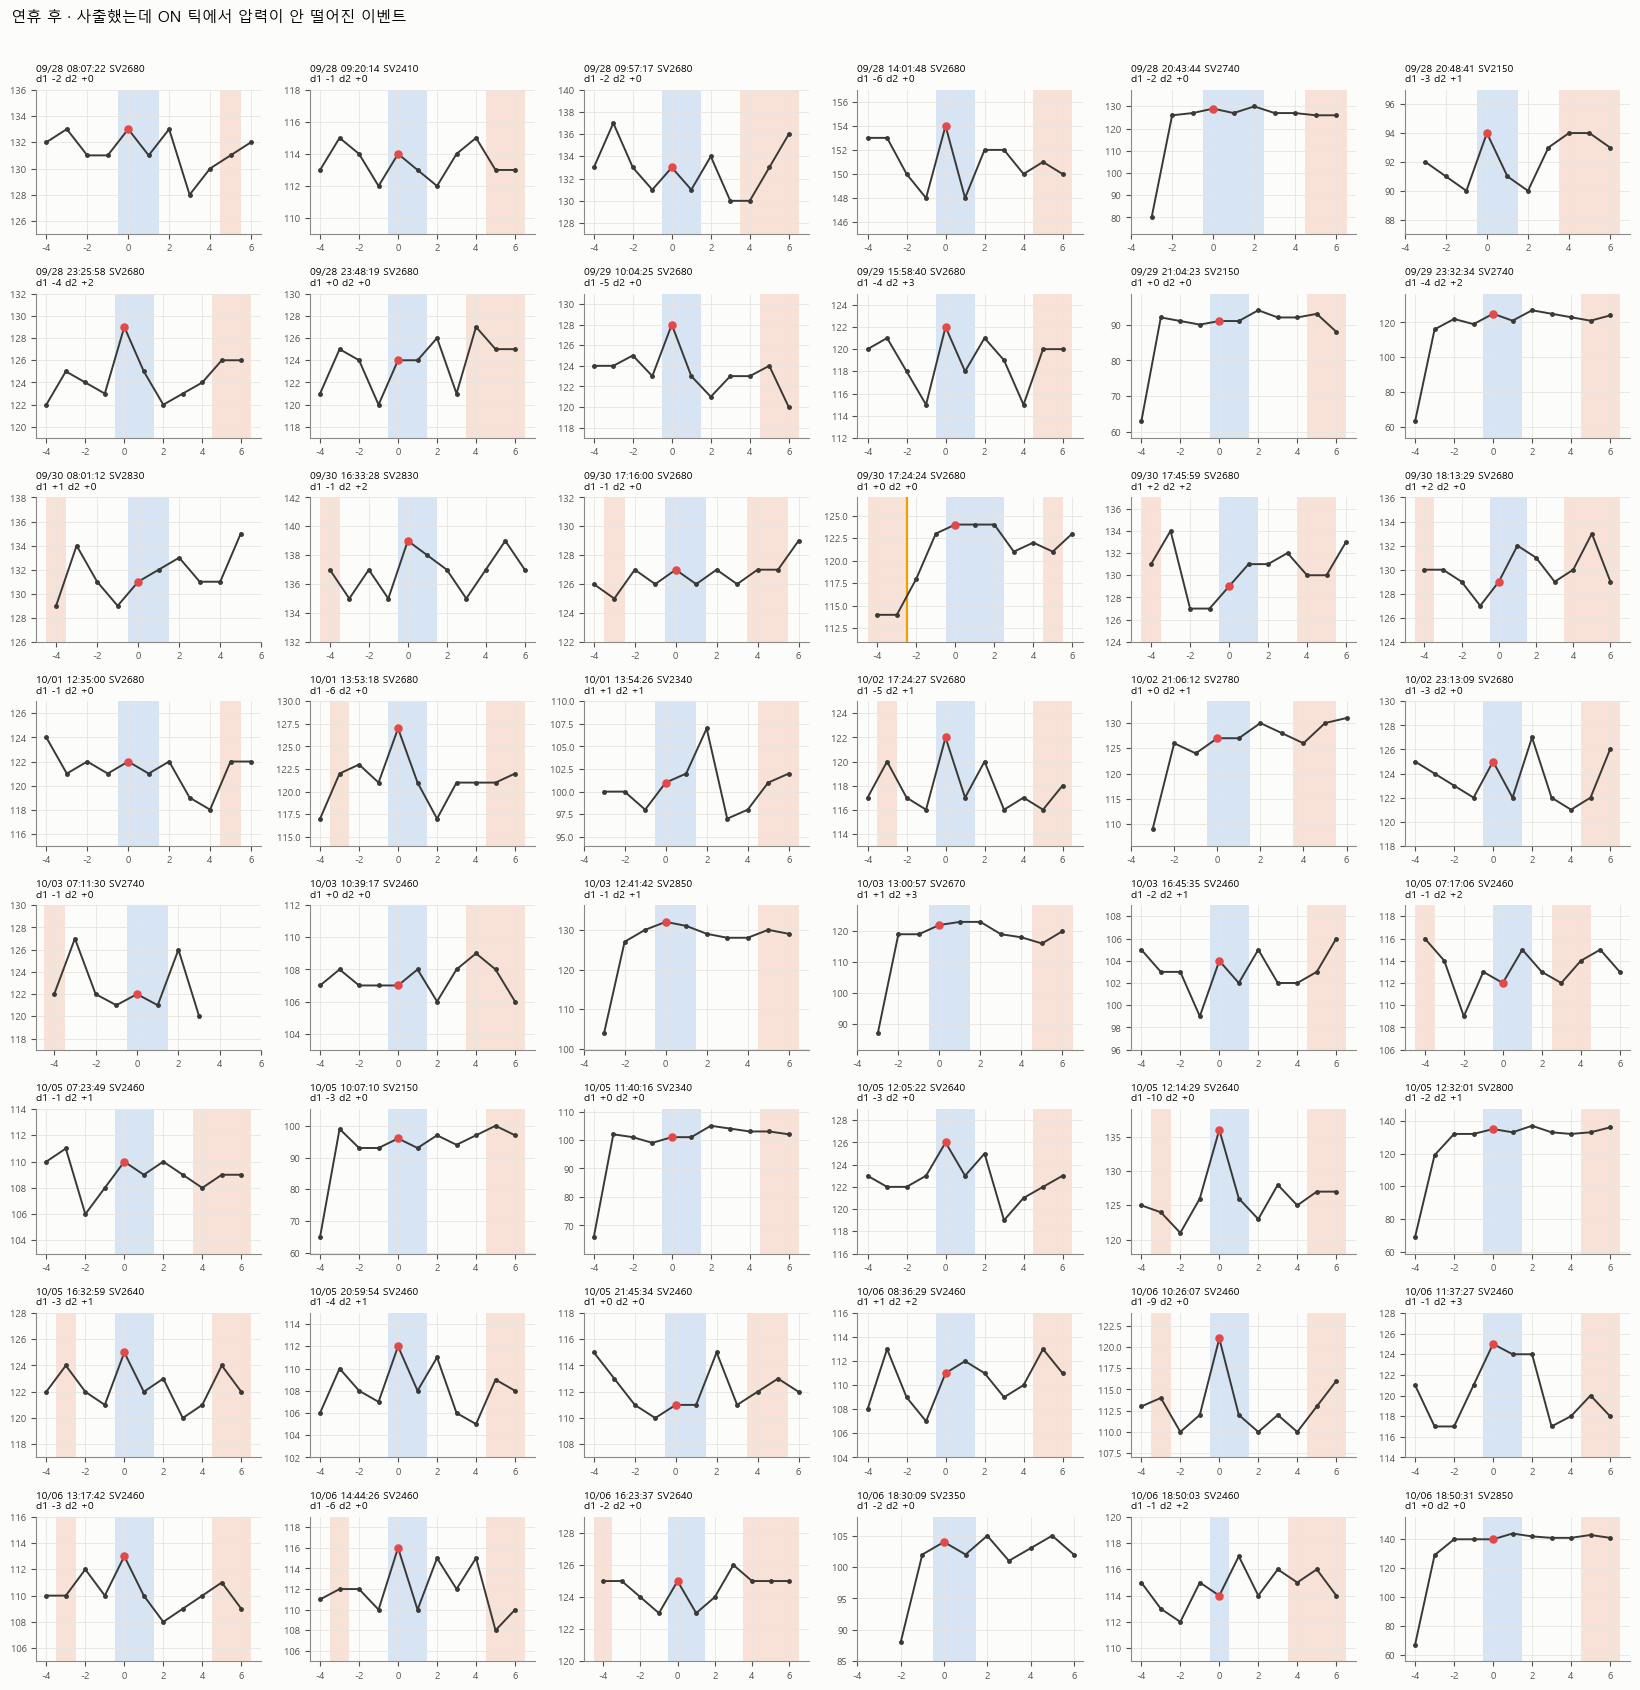

In [9]:
def title(r): return f"{pd.Timestamp(r.Time):%m/%d %H:%M:%S} SV{r.SV:.0f}\nd1 {r.min_d1:+.0f} d2 {r.min_d2:+.0f}"
smp = nd.sample(48, random_state=1).sort_values('Time')
fig_samples(T, smp.s.values, [title(r) for r in smp.itertuples()], suptitle='연휴 후 · 사출했는데 ON 틱에서 압력이 안 떨어진 이벤트'); plt.show()

### 샘플에서 보이는 패턴: 연휴 후엔 사출 순간 압력이 먼저 "튀어 오른다"
위 샘플 상당수가 S1 시작 틱(빨간 점)에서 압력이 3~6 눈금 **올라갔다가** 다음 틱에 원래 수준으로 돌아온다. 그러면 dPT1 은 −3~−6 이 찍히지만 dPT2(2틱 전 대비)는 0 근처가 된다.

In [10]:
ev['d1_start'] = T.dPT1.values[ev.s.values]
rows = []
for er in ['연휴 전', '연휴 후']:
    e = ev[ev.era == er]; nd_ = e[e.min_d2 >= 0]
    rows.append({'구간': er, 'S1 시작 틱 dPT1 ≥ +3 (전체 이벤트)%': (e.d1_start >= 3).mean() * 100,
                 'S1 시작 틱 dPT1 ≥ +3 (무하락 이벤트 중)%': (nd_.d1_start >= 3).mean() * 100,
                 '무하락(dPT2≥0) 중 dPT1 최저 ≤ -3 %': (nd_.min_d1 <= -3).mean() * 100})
pd.DataFrame(rows).set_index('구간').round(1)

,S1 시작 틱 dPT1 ≥ +3 (전체 이벤트)%,S1 시작 틱 dPT1 ≥ +3 (무하락 이벤트 중)%,무하락(dPT2≥0) 중 dPT1 최저 ≤ -3 %
구간,,,
연휴 전,10.3,27.9,90.7
연휴 후,26.1,56.6,35.0


- 연휴 후 S1 이벤트의 26% 가 시작 틱에서 +3 이상 튀어 오른다 (연휴 전 10%). dPT2 기준 "무하락" 이벤트 중에서는 57%.
- 그래서 **dPT2 기준 무하락 12.5% 중 상당수는 "튀었다가 돌아옴"** 이고, dPT1 으로 보면 그중 35% 는 −3 이하 하락이 찍힌다 → dPT1 기준 무하락은 5.5%.
- 사출 순간 압력 응답의 **모양 자체가 바뀌었다** (연휴 전: 바로 하락 / 연휴 후: 상승 후 하락, 또는 하락이 늦게). AE 에 dPT1 이 들어가면 이 모양 변화도 학습/탐지 대상이 된다.

### 비교: 같은 연휴 후, 정상적으로 떨어진 이벤트 24건 / 연휴 전 이벤트 24건

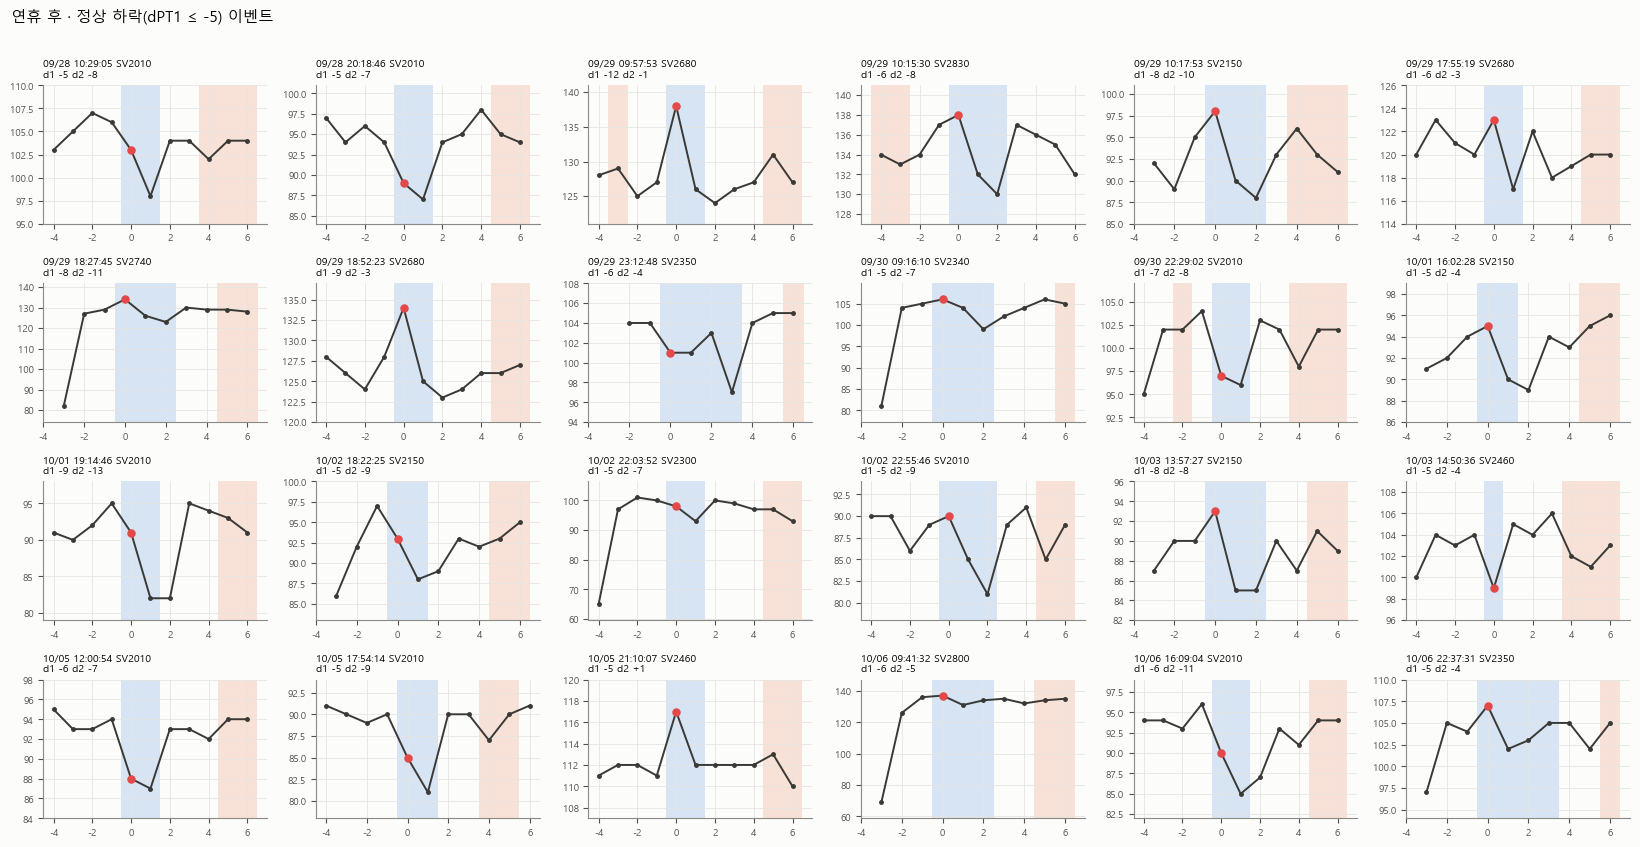

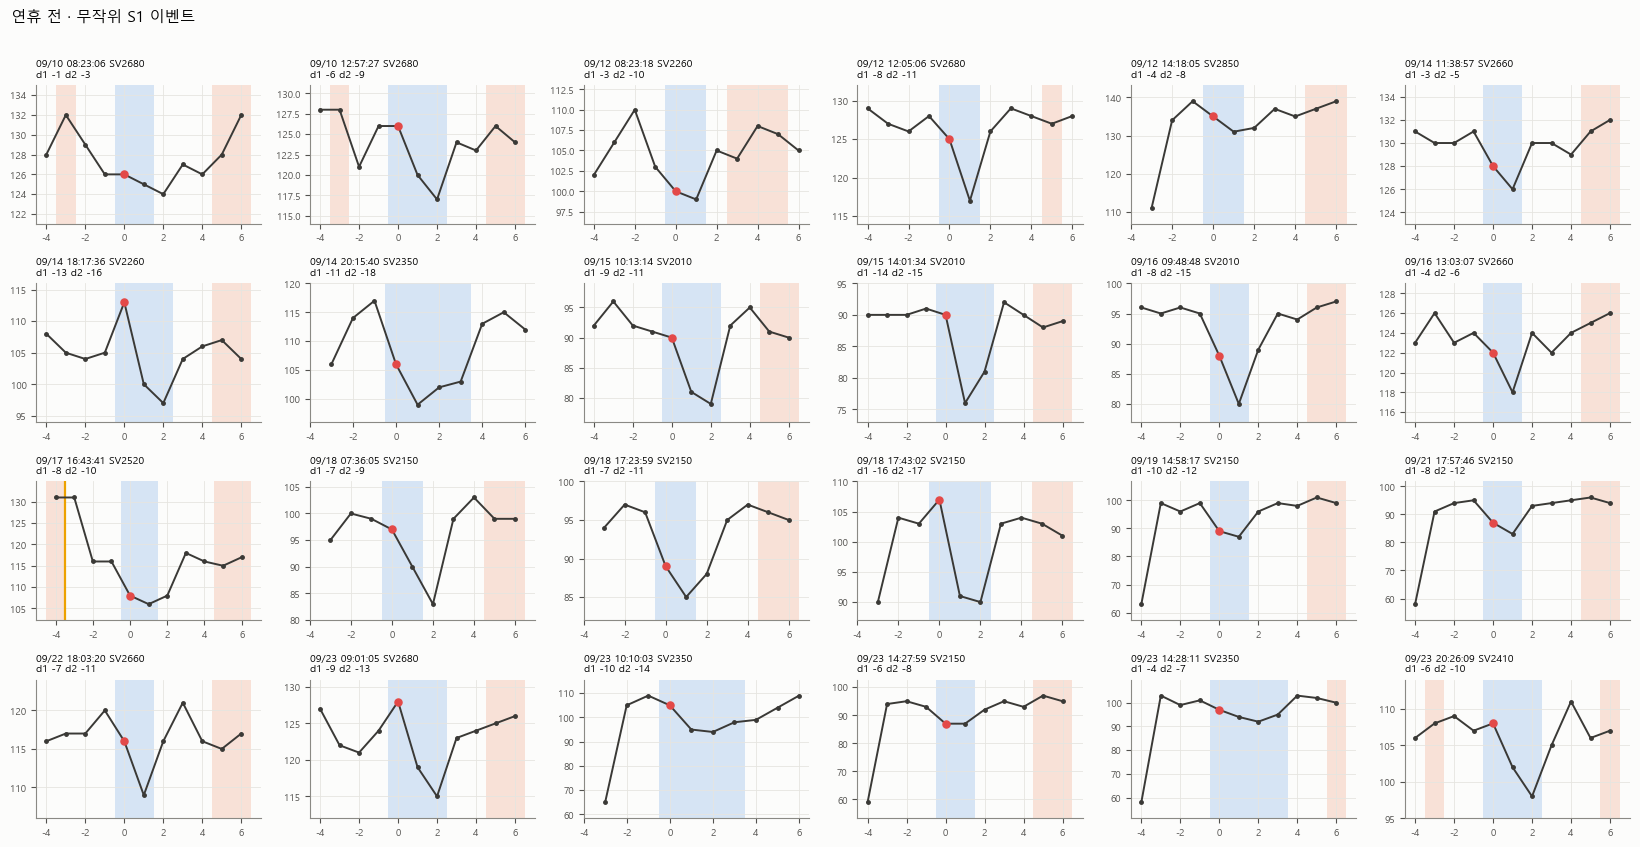

In [11]:
ok_post = ev[(ev.era == '연휴 후') & (ev.min_d1 <= -5)].sample(24, random_state=2).sort_values('Time')
fig_samples(T, ok_post.s.values, [title(r) for r in ok_post.itertuples()], suptitle='연휴 후 · 정상 하락(dPT1 ≤ -5) 이벤트'); plt.show()
pre = ev[ev.era == '연휴 전'].sample(24, random_state=3).sort_values('Time')
fig_samples(T, pre.s.values, [title(r) for r in pre.itertuples()], suptitle='연휴 전 · 무작위 S1 이벤트'); plt.show()

### 같은 레시피(SV >2600) 를 연휴 전/후로 나란히

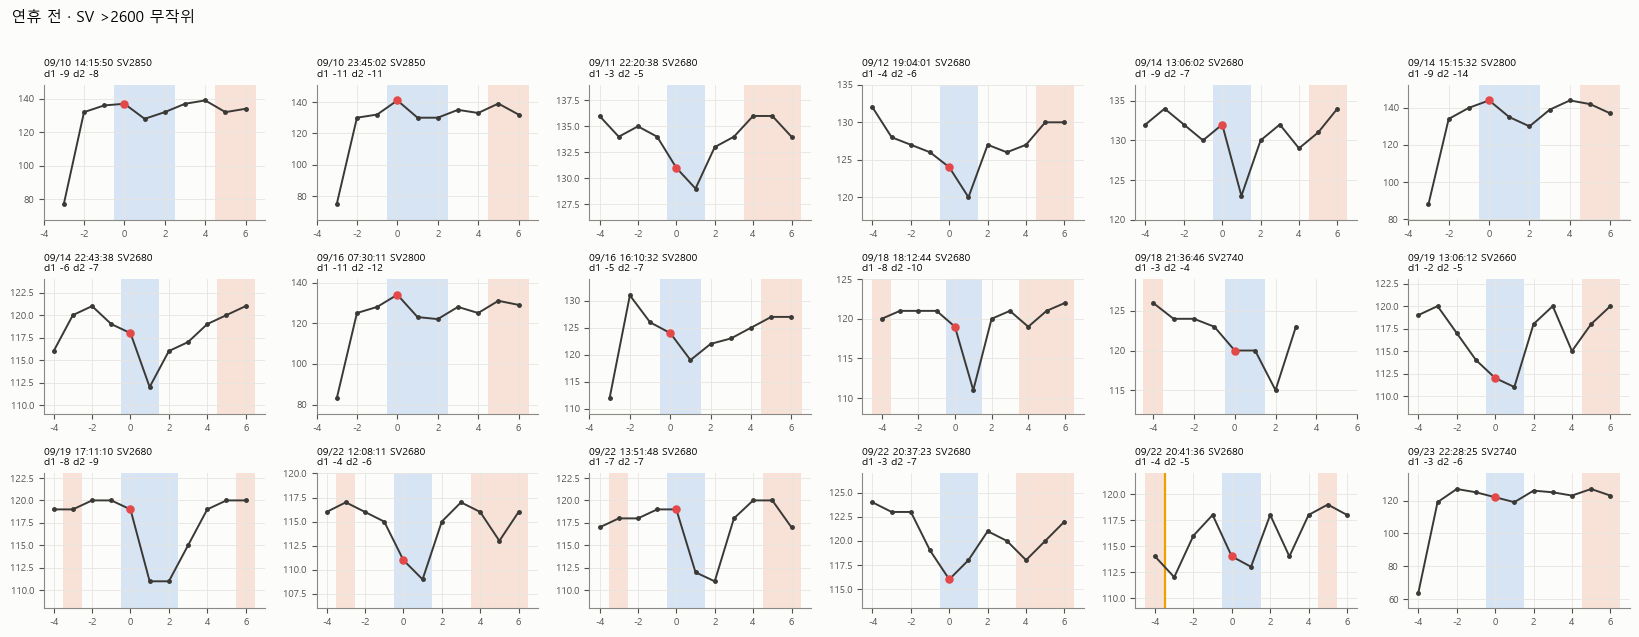

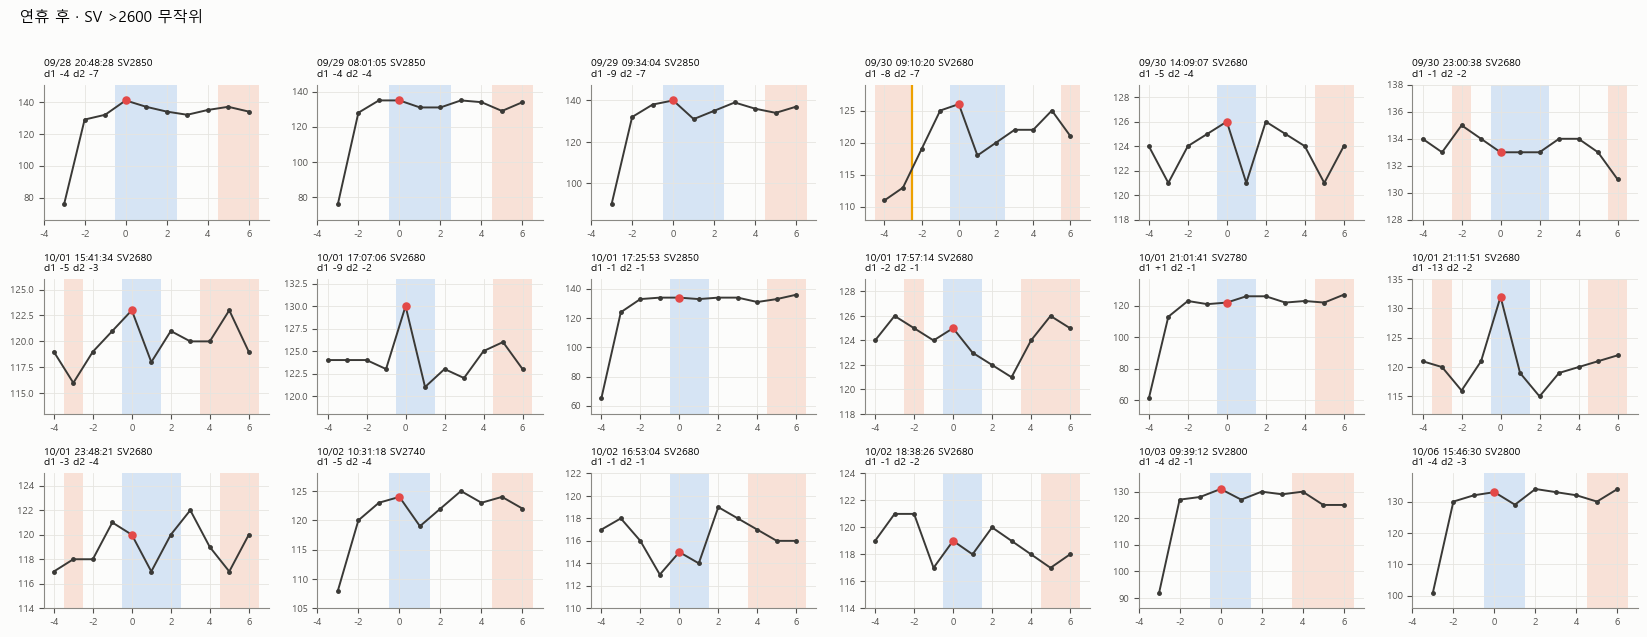

In [12]:
a = ev[(ev.era == '연휴 전') & (ev.svb == '>2600')].sample(18, random_state=4).sort_values('Time')
b = ev[(ev.era == '연휴 후') & (ev.svb == '>2600')].sample(18, random_state=4).sort_values('Time')
fig_samples(T, a.s.values, [title(r) for r in a.itertuples()], suptitle='연휴 전 · SV >2600 무작위'); plt.show()
fig_samples(T, b.s.values, [title(r) for r in b.itertuples()], suptitle='연휴 후 · SV >2600 무작위'); plt.show()

## 3. 사출이 없는데 떨어진 경우 — 정상 대비 얼마나, 피처로 얼마나 줄어드나

S1 OFF 틱(Tick_Index ≥ 1) 중 dPT1 ≤ −5 를 원인별로 나눴다. 순서대로 피처를 하나씩 넣는다고 보고 빼 나간다:
1. `Pair_Inj_Flag` (짝펌프 P2 사출 중)
2. `dSV2 ≠ 0` (SV 변경 틱 또는 다음 틱)
3. `FT_Settled = 0` (증압 중, tick 1~3)
4. S1 꺼진 직후 1~2틱 — **대응 피처 없음** (참고로만 빼 봄)

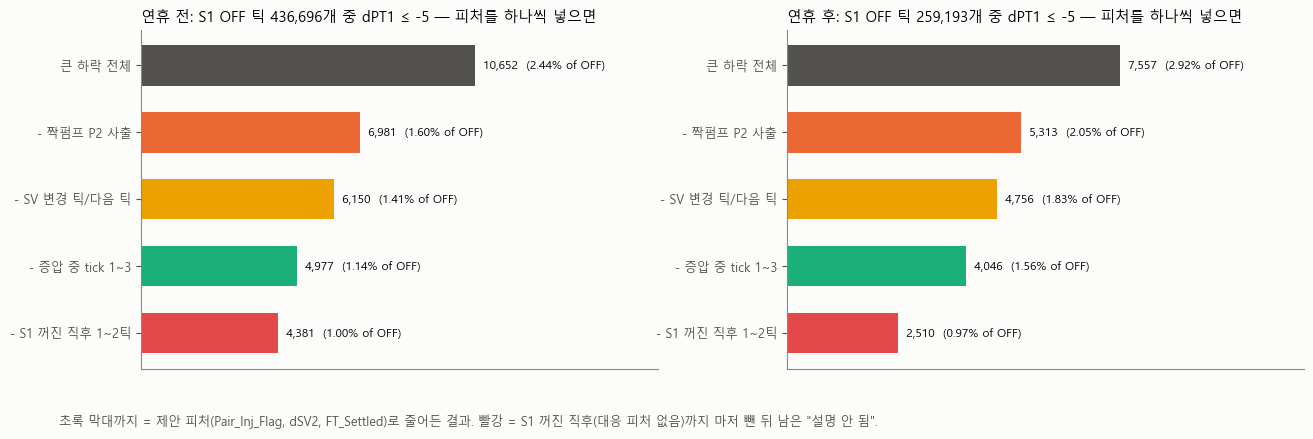

In [13]:
fig_funnel(J); plt.show()

In [14]:
funnel_table(J).T

구간,연휴 전,연휴 후
S1 OFF 틱,436696.00,259193.00
정상(>-5),426044.00,251636.00
큰 하락(≤-5),10652.00,7557.00
큰 하락 %,2.44,2.92
- 짝펌프 P2 사출 빼면,6981.00,5313.00
- SV 변경 틱/다음 틱 빼면,6150.00,4756.00
- 증압 중 tick 1~3 빼면,4977.00,4046.00
- S1 꺼진 직후 1~2틱 빼면,4381.00,2510.00
남은 % (OFF 틱 대비),1.00,0.97
남은 비율 (큰 하락 대비)%,41.13,33.21


### 크기 구간별 × 원인 (건수, 20일 합)

In [15]:
mag_cat_table(J)

cat         짝펌프 P2 사출 (Pair_Inj_Flag)  SV 변경 틱/다음 틱 (dSV2≠0)  증압 중 tick 1~3 (FT_Settled=0)  S1 꺼진 직후 1~2틱 (피처 없음)  설명 안 됨     합  OFF 틱 1만 개당
era  mag                                                                                                                                    
연휴 전 ≤-10                           0                    521                             9                      1       1   532         12.2
     -9~-8                         23                    112                            10                      8      29   182          4.2
     -7                           215                     58                            59                     37     253   622         14.2
     -6                          1052                     69                           357                    147    1266  2891         66.2
     -5                          2381                     71                           738                    403    2832  6425        147.1
연휴 후 ≤-10                           0                    176                             1                     28       2   207          8.0
     -9~-8                         14                     90                             5                    102      13   224          8.6
     -7                           126                     81                            41                    195      95   538         20.8
     -6                           626                    113                           178                    380     666  1963         75.7
     -5                          1478                     97                           485                    831    1734  4625        178.4

- 사출 없는 틱의 **97~98% 는 정상(dPT1 > −5)**, 큰 하락은 2.4% / 2.9%.
- 피처 3개(Pair_Inj, dSV2, FT_Settled)를 넣으면 큰 하락이 10,652 → 4,977 (연휴 전), 7,557 → 4,046 (연휴 후) 로 절반 이하. S1 꺼진 직후까지 빼면 OFF 틱의 약 1.0%.
- **−10 이하의 큰 하락은 거의 전부 SV 변경**(연휴 전 532건 중 521건) → `dSV2` 가 결정적.
- 짝펌프 사출은 −5~−7 을 많이 설명한다 (연휴 전 3,671건).
- 연휴 후 "S1 꺼진 직후" 가 늘었다 (596 → 1,536) — 하락이 늦게 오는 현상 때문. 이건 지금 피처 구성으로는 설명 못 한다.
- **남는 "설명 안 됨" 의 크기**: −5 와 −6 이 대부분이고 −8 이하는 20일 동안 45건, −10 이하는 3건.

> **질문하신 4,566 / 1,932 건**: 맞다. 위 표의 "설명 안 됨" 열에서 −5 (연휴 전 2,832 + 후 1,734 = 4,566), −6 (1,266 + 666 = 1,932) 이다.

## 4. 설명 안 되는 하락은 언제 생기나

모집단 = 위 4가지 원인 어디에도 해당 안 되는 S1 OFF 틱 (전부 BuildUp 중 — 이 분석은 BuildUp 틱만 대상). 그중 dPT1 ≤ −5 인 비율을 조건별로 비교했다. 특정 조건에 몰려 있다면 그 조건의 막대만 튀어야 한다.

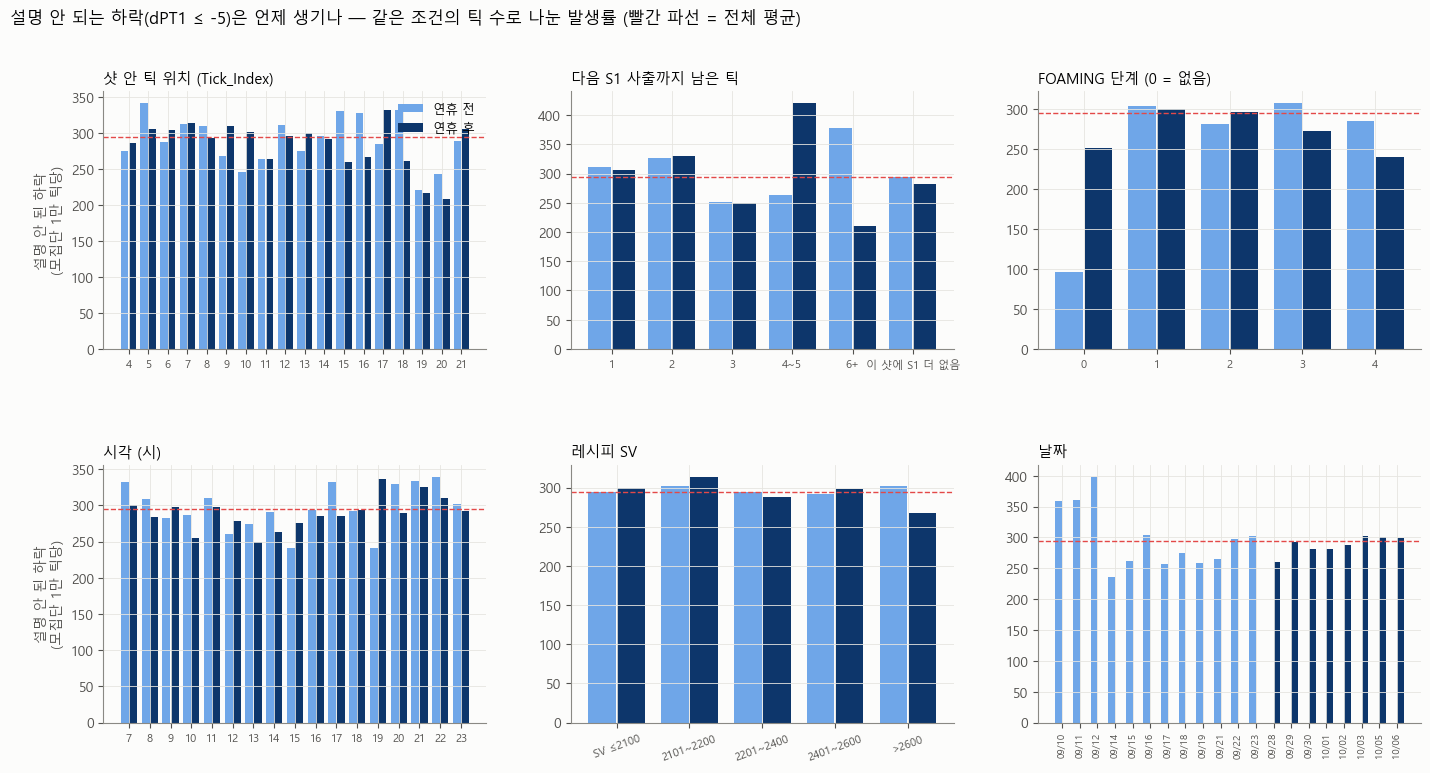

In [16]:
fig, tabs, un = fig_when(J, T); plt.show()

In [17]:
for k, t in tabs.items():
    print('──', k); display(t['1만 틱당'].round(0).T)

── Tick_Index


Tick_Index,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
era,,,,,,,,,,,,,,,,,,
연휴 전,275.0,341.0,287.0,312.0,310.0,269.0,247.0,263.0,312.0,276.0,296.0,330.0,328.0,285.0,332.0,222.0,244.0,289.0
연휴 후,287.0,307.0,305.0,314.0,293.0,310.0,302.0,264.0,296.0,300.0,292.0,260.0,267.0,332.0,261.0,217.0,209.0,306.0


── to_next_cat


to_next_cat,1,2,3,4~5,6+,이 샷에 S1 더 없음
era,,,,,,
연휴 전,312.0,326.0,251.0,263.0,378.0,295.0
연휴 후,307.0,330.0,249.0,420.0,210.0,282.0


── F_phase


...

hour,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
era,,,,,,,,,,,,,,,,,
연휴 전,333.0,309.0,283.0,286.0,310.0,260.0,274.0,291.0,241.0,293.0,332.0,292.0,241.0,330.0,333.0,339.0,302.0
연휴 후,301.0,284.0,297.0,256.0,297.0,279.0,249.0,263.0,276.0,286.0,286.0,294.0,336.0,289.0,325.0,310.0,291.0


── svb


svb,SV ≤2100,2101~2200,2201~2400,2401~2600,>2600
era,,,,,
연휴 전,295.0,302.0,295.0,292.0,303.0
연휴 후,300.0,313.0,288.0,298.0,268.0


── day


day,2026-09-10,2026-09-11,2026-09-12,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-19,2026-09-21,2026-09-22,2026-09-23,2026-09-28,2026-09-29,2026-09-30,2026-10-01,2026-10-02,2026-10-03,2026-10-05,2026-10-06
era,,,,,,,,,,,,,,,,,,,,
연휴 전,359.0,361.0,398.0,237.0,261.0,304.0,257.0,275.0,259.0,265.0,297.0,302.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
연휴 후,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,260.0,292.0,282.0,281.0,288.0,302.0,300.0,299.0


- **틱 위치 · 다음 사출까지의 거리 · FOAMING 단계 · 시간대 · 레시피 · 날짜 어디에도 뚜렷이 몰리지 않는다.** 대부분의 구간이 1만 틱당 250~330 (= 2.5~3.3%), 전체 범위도 약 210~420 안이고, 연휴 전/후에 같은 구간이 같이 튀는 경우가 없다.
  - 눈에 띄는 것: 연휴 전 FOAMING 단계 0(=사출 단계 밖)이 97 로 낮음, 9/10~9/12 가 360~400 으로 약간 높음 — 크지 않고 연휴 후엔 재현되지 않는다.
- 한 샷에 몰려 나오는지도 확인 (무작위로 흩어졌다면 포아송 분포를 따른다):

In [18]:
per_shot_cluster(J)

,샷당 건수,관측 샷 수,무작위(포아송) 기대
0,0,50304,50419.9
1,1,6325,6105.1
2,2,277,369.6
3,3,4,14.9
4,4,0,0.5
5,5+,0,NaN


In [19]:
base = J[J.cat == '설명 안 됨']
u = base[base.dPT1 <= -BIG]
nxt = T.dPT1.shift(-1).values[u.index]; same = (T.shot.shift(-1).values[u.index] == u.shot.values)
print('설명 안 되는 하락 다음 틱의 dPT1: 평균', round(np.nanmean(nxt[same]), 2), ' / +3 이상 회복 비율', round(np.nanmean(nxt[same] >= 3) * 100, 1), '%')
print('전체 PT 값 단위: 정수 (최소 변화 1 눈금)')

설명 안 되는 하락 다음 틱의 dPT1: 평균 1.56  / +3 이상 회복 비율 37.5 %
전체 PT 값 단위: 정수 (최소 변화 1 눈금)


- 샷당 개수가 무작위(포아송) 기대와 거의 같다 — **한 샷에 몰리지 않는다.**
- 하락 다음 틱은 평균 +1.6 으로 일부 되돌아간다 (+3 이상 회복은 37.5%).
- 즉 남는 "설명 안 되는 하락" 은 **시간·조건과 무관하게 고르게, 샷마다 무작위로 생기는 출렁임** — 압력 센서/제어의 정상 노이즈로 보는 게 맞다.

### 샘플 — 설명 안 되는 하락 36건 (무작위, 빨간 점 = 그 틱)

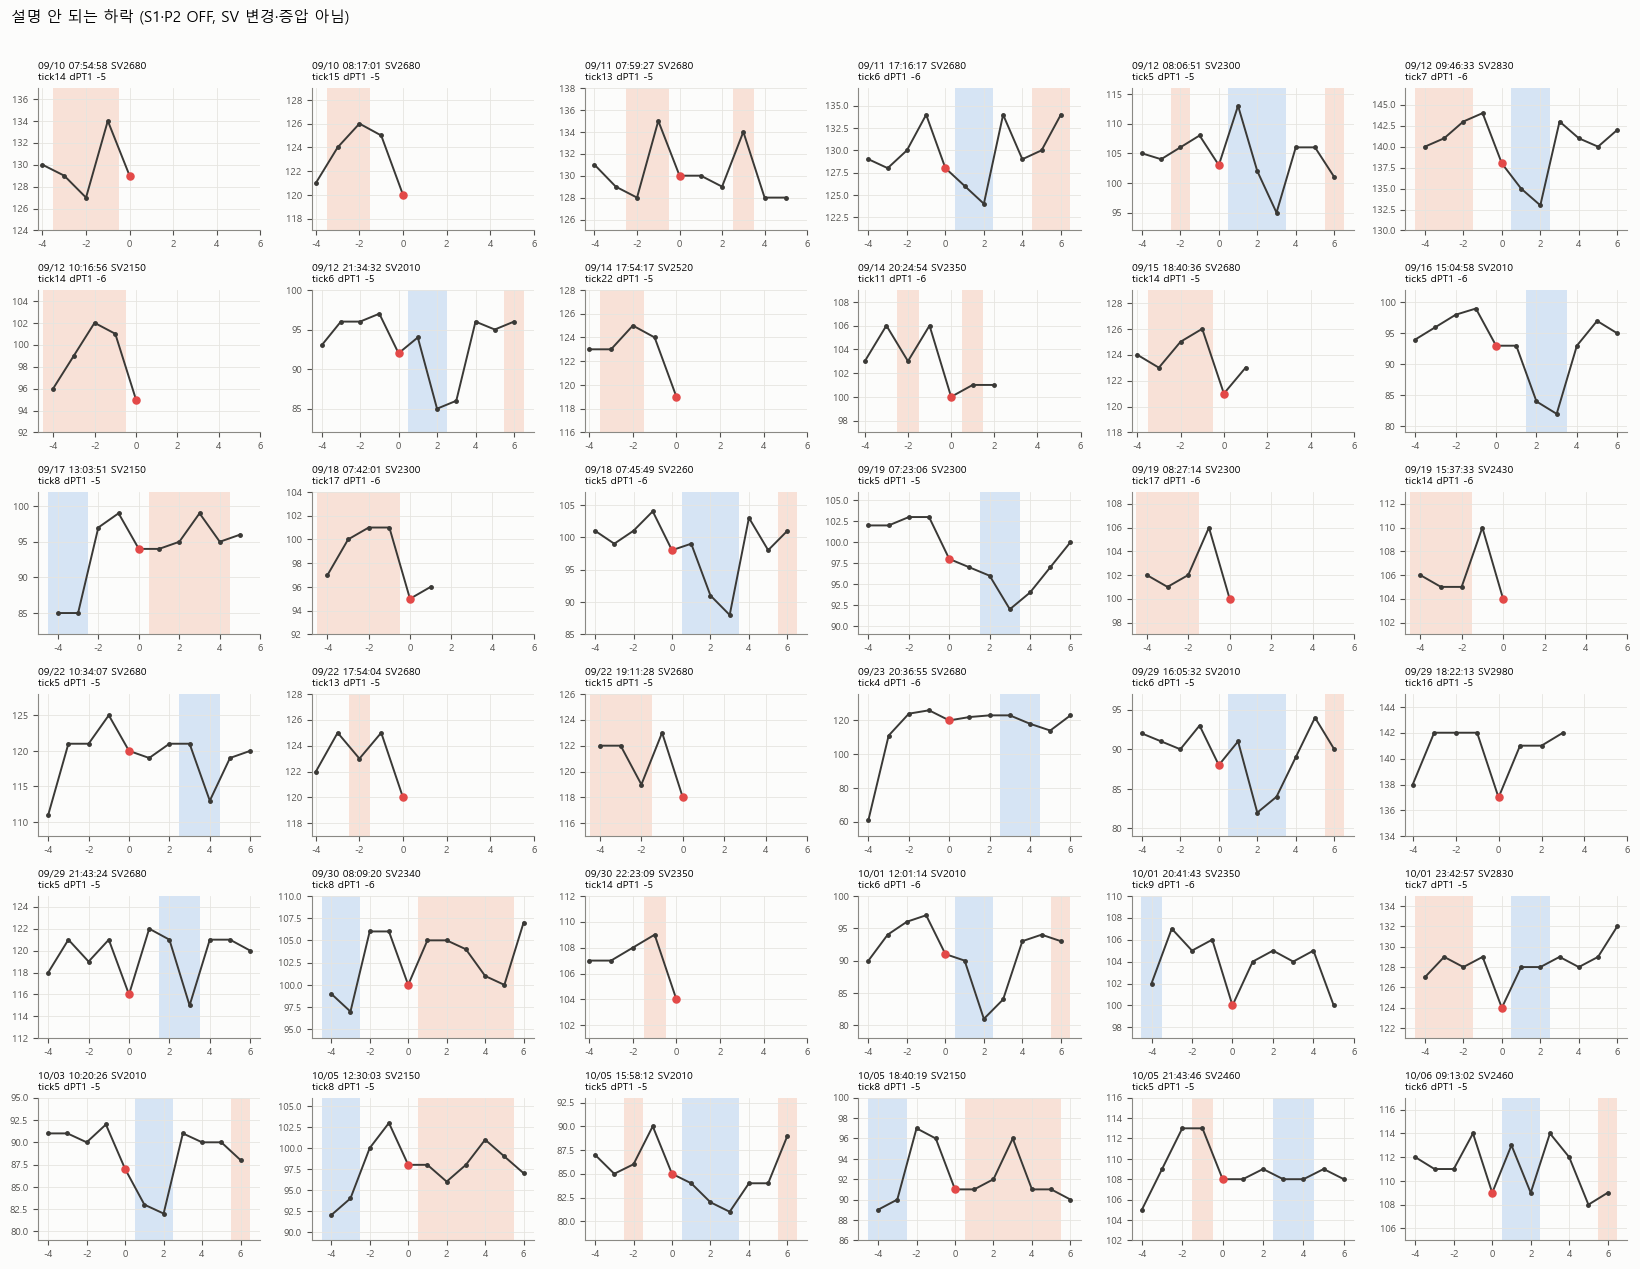

In [20]:
smp = u.sample(36, random_state=5).sort_values('Time')
fig_samples(T, smp.index.values, [f"{pd.Timestamp(r.Time):%m/%d %H:%M:%S} SV{r.SV:.0f}\ntick{r.Tick_Index} dPT1 {r.dPT1:+.0f}" for r in smp.itertuples()],
            suptitle='설명 안 되는 하락 (S1·P2 OFF, SV 변경·증압 아님)'); plt.show()

## 5. 정리

| 질문 | 답 |
|---|---|
| 사출하면 얼마나 떨어지나 | 연휴 전: ON 틱 최저 dPT1 중앙 −8 (90% 가 ≤−5). 연휴 후: 중앙 −4 (42% 가 ≤−5), 둘째 ON 틱에서 떨어짐 |
| dPT1 만으로 되나 | **된다.** 이벤트 검출은 dPT1 이 dPT2 와 같거나 낫다. 틱 정보량은 dPT2 가 더 크니, 이미 있는 dPT2 는 유지 권장 |
| 연휴 후 무하락 12% 는 진짜인가 | **진짜지만 dPT2 기준 숫자다.** 9/28 부터 매일 10.6~16.4%, 87% 가 고유량 레시피(SV >2400), 직전 대비 1~2 눈금. 그중 57% 는 사출 순간 압력이 먼저 튀어 올랐다 돌아오는 모양 → **dPT1 기준 무하락은 5.5%** |
| 사출 없는데 떨어짐 | OFF 틱의 2.4~2.9%. Pair_Inj·dSV2·FT_Settled 로 절반 이상 설명 → 남는 건 OFF 틱의 1.1~1.6% (S1 꺼진 직후까지 빼면 약 1.0%) |
| 설명 안 되는 하락은 언제 | 시간·날짜·레시피·샷 위치·사출 전후 어디에도 몰리지 않음, 샷당 무작위 분포, 다음 틱 바로 회복 → 정상 노이즈 |

**AE 관점**: 설명 안 되는 −5~−6 은 정상 데이터에도 고르게 섞여 있는 노이즈라 AE 가 "원래 이 정도는 흔들린다"로 배운다 — 한 틱으로는 이상과 구분 못 한다. 이상은 (a) −8 이하처럼 정상에서 드문 크기, (b) 노이즈 빈도가 평소보다 늘어남, (c) 사출 ON 인데 안 떨어지는 틱이 계속 쌓임 — 으로 드러난다. 그래서 틱 MSE 하나보다 **샷 평균 MSE / 시간당 고오차 틱 수**를 봐야 한다.